## Loading the pretrained Visiion Transfomer

In [8]:
# ============================================================
# PHASE 3 — ADVANCED MODEL
# Cell 1: Environment & Existing Artifact Verification
# ============================================================

import os
import json
import torch
import torchvision

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_DIR = r"C:\Users\rajva\Desktop\image-captioning Project"
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebook")

CHECKPOINT_DIR = os.path.join(NOTEBOOK_DIR, "checkpoints")
FEATURE_DIR = os.path.join(NOTEBOOK_DIR, "cached_features")

print("Project directory:")
print(PROJECT_DIR)

print("\nNotebook directory:")
print(NOTEBOOK_DIR)


# ------------------------------------------------------------
# 2. CPU verification
# ------------------------------------------------------------

device = torch.device("cpu")

print("\nDevice:", device)
print("CUDA available:", torch.cuda.is_available())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)


# ------------------------------------------------------------
# 3. Existing Phase 2 files
# ------------------------------------------------------------

required_files = {
    "Processed captions":
        os.path.join(NOTEBOOK_DIR, "processed_captions.pkl"),

    "Vocabulary":
        os.path.join(NOTEBOOK_DIR, "vocabulary.json"),

    "Train features":
        os.path.join(FEATURE_DIR, "train_features.pt"),

    "Validation features":
        os.path.join(FEATURE_DIR, "val_features.pt"),

    "Test features":
        os.path.join(FEATURE_DIR, "test_features.pt"),

    "Baseline checkpoint":
        os.path.join(CHECKPOINT_DIR, "best_baseline_model.pth"),

    "Baseline metrics":
        os.path.join(NOTEBOOK_DIR, "baseline_metrics.json"),

    "Baseline predictions":
        os.path.join(NOTEBOOK_DIR, "baseline_predictions.json"),
}

print("\n" + "=" * 60)
print("PHASE 2 ARTIFACT CHECK")
print("=" * 60)

all_found = True

for name, path in required_files.items():
    exists = os.path.exists(path)

    status = "FOUND" if exists else "MISSING"

    print(f"{status:8} | {name}")
    print(f"         {path}")

    if not exists:
        all_found = False


# ------------------------------------------------------------
# 4. Load baseline metrics for fixed benchmark
# ------------------------------------------------------------

metrics_path = required_files["Baseline metrics"]

if os.path.exists(metrics_path):
    with open(metrics_path, "r") as f:
        baseline_metrics = json.load(f)

    print("\n" + "=" * 60)
    print("FIXED BASELINE BENCHMARK")
    print("=" * 60)

    for metric, value in baseline_metrics.items():
        print(f"{metric:10}: {value}")


# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 60)

if all_found:
    print("✓ All required Phase 2 artifacts are available.")
    print("✓ Phase 3 can proceed.")
else:
    print("✗ One or more required files are missing.")
    print("Do NOT continue until the missing files are resolved.")

Project directory:
C:\Users\rajva\Desktop\image-captioning Project

Notebook directory:
C:\Users\rajva\Desktop\image-captioning Project\notebook

Device: cpu
CUDA available: False
PyTorch version: 2.13.0+cpu
Torchvision version: 0.28.0+cpu

PHASE 2 ARTIFACT CHECK
FOUND    | Processed captions
         C:\Users\rajva\Desktop\image-captioning Project\notebook\processed_captions.pkl
FOUND    | Vocabulary
         C:\Users\rajva\Desktop\image-captioning Project\notebook\vocabulary.json
FOUND    | Train features
         C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\train_features.pt
FOUND    | Validation features
         C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\val_features.pt
FOUND    | Test features
         C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\test_features.pt
FOUND    | Baseline checkpoint
         C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints\best_baseline_model.pth
F

In [5]:
# ============================================================
# PHASE 3 — CELL 2
# Load and verify pretrained Vision Transformer (ViT-B/16)
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import vit_b_16, ViT_B_16_Weights

# CPU only
device = torch.device("cpu")

# Load pretrained ViT-B/16
weights = ViT_B_16_Weights.DEFAULT
vit_encoder = vit_b_16(weights=weights)

# Remove classification head to obtain visual representations
vit_encoder.heads = nn.Identity()

# Freeze pretrained parameters
vit_encoder.eval()
for param in vit_encoder.parameters():
    param.requires_grad = False

# Display model configuration
print("Vision Transformer loaded successfully.")

print("\nModel: ViT-B/16")
print("Device:", device)
print("Pretrained weights:", weights)
print("Hidden dimension:", vit_encoder.hidden_dim)
print("Patch size:", vit_encoder.patch_size)
print("Image size:", vit_encoder.image_size)

print(
    "\nAll parameters frozen:",
    all(not p.requires_grad for p in vit_encoder.parameters())
)

print(
    "Classification head removed:",
    isinstance(vit_encoder.heads, nn.Identity)
)

Vision Transformer loaded successfully.

Model: ViT-B/16
Device: cpu
Pretrained weights: ViT_B_16_Weights.IMAGENET1K_V1
Hidden dimension: 768
Patch size: 16
Image size: 224

All parameters frozen: True
Classification head removed: True


In [6]:
# ============================================================
# PHASE 3 — CELL 3
# Verify ViT output shape and feature representation
# ============================================================

import torch

# Create one dummy image: batch size 1, RGB, 224 x 224
dummy_image = torch.randn(1, 3, 224, 224, device=device)

vit_encoder.eval()

with torch.inference_mode():
    dummy_output = vit_encoder(dummy_image)

print("Input shape:", tuple(dummy_image.shape))
print("ViT output shape:", tuple(dummy_output.shape))
print("Output data type:", dummy_output.dtype)
print("Output device:", dummy_output.device)
print("All output values finite:", torch.isfinite(dummy_output).all().item())

# Verify expected global representation
assert dummy_output.shape == (1, 768), "Unexpected ViT output shape!"
assert torch.isfinite(dummy_output).all(), "Output contains NaN or Inf!"

print("\nGlobal feature verification passed.")


Input shape: (1, 3, 224, 224)
ViT output shape: (1, 768)
Output data type: torch.float32
Output device: cpu
All output values finite: True

Global feature verification passed.


## Extract the spatial patch token

In [7]:
# ============================================================
# PHASE 3 — CELL 4
# Extract spatial patch tokens from pretrained ViT-B/16
# ============================================================

import torch

def extract_vit_patch_tokens(vit_model, images):
    """
    Extract spatial patch representations from ViT-B/16.

    Args:
        vit_model: Pretrained torchvision ViT with its
                   classification head replaced by Identity.
        images: Tensor shaped (batch_size, 3, 224, 224).

    Returns:
        Patch tokens shaped (batch_size, 196, 768).
    """
    vit_model.eval()

    with torch.inference_mode():
        # Convert image into patch embeddings
        x = vit_model._process_input(images)

        # Add the class token
        batch_size = x.shape[0]
        cls_token = vit_model.class_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_token, x], dim=1)

        # Apply pretrained positional embeddings and Transformer encoder
        x = vit_model.encoder(x)

        # Remove class token; retain spatial patch tokens
        patch_tokens = x[:, 1:, :]

    return patch_tokens


# Verify using the existing dummy image
patch_tokens = extract_vit_patch_tokens(vit_encoder, dummy_image)

print("Input shape:", tuple(dummy_image.shape))
print("Patch token shape:", tuple(patch_tokens.shape))
print("Number of spatial patches:", patch_tokens.shape[1])
print("Features per patch:", patch_tokens.shape[2])
print("All values finite:", torch.isfinite(patch_tokens).all().item())

assert patch_tokens.shape == (1, 196, 768)
assert torch.isfinite(patch_tokens).all()

print("\nSpatial patch-token verification passed.")

Input shape: (1, 3, 224, 224)
Patch token shape: (1, 196, 768)
Number of spatial patches: 196
Features per patch: 768
All values finite: True

Spatial patch-token verification passed.


## Verify image preprocessing

In [8]:
# ============================================================
# PHASE 3 — CELL 5
# Verify pretrained ViT image preprocessing
# ============================================================

from torchvision.models import ViT_B_16_Weights

# Official preprocessing for the pretrained weights
vit_weights = ViT_B_16_Weights.DEFAULT
vit_transform = vit_weights.transforms()

print("Preprocessing configuration:")
print(vit_transform)

print("\nExpected image size:", vit_encoder.image_size)
print("Expected channels: 3 (RGB)")
print("Expected patch size:", vit_encoder.patch_size)

print("\nPreprocessing verification information displayed.")

Preprocessing configuration:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

Expected image size: 224
Expected channels: 3 (RGB)
Expected patch size: 16

Preprocessing verification information displayed.


## Inspect existing image preprocessing

In [9]:
# ============================================================
# PHASE 3 — CELL 6
# Inspect existing preprocessing variables
# ============================================================

print("Existing notebook variables relevant to image preprocessing:\n")

keywords = [
    "transform",
    "preprocess",
    "dataset",
    "dataloader",
    "image_dir",
    "image_path",
    "train_df",
    "val_df",
    "test_df",
]

for name, value in list(globals().items()):
    if any(keyword in name.lower() for keyword in keywords):
        if not name.startswith("_"):
            print(f"{name}: {type(value).__name__}")

print("\nProject directory exists:", os.path.isdir(PROJECT_DIR))
print("Notebook directory exists:", os.path.isdir(NOTEBOOK_DIR))

Existing notebook variables relevant to image preprocessing:

vit_transform: ImageClassification

Project directory exists: True
Notebook directory exists: True


## Inspect the saved caption dataset

In [10]:
# ============================================================
# PHASE 3 — CELL 7
# Inspect saved caption dataset and image paths
# ============================================================

import os
import pandas as pd

captions_path = os.path.join(NOTEBOOK_DIR, "processed_captions.pkl")

captions_df = pd.read_pickle(captions_path)

print("Dataset shape:", captions_df.shape)
print("\nColumns:")
print(captions_df.columns.tolist())

print("\nSplit distribution:")
print(captions_df["split"].value_counts())

print("\nUnique images per split:")
print(captions_df.groupby("split")["image"].nunique())

print("\nSample image filenames:")
print(captions_df[["image", "split", "caption"]].head(5).to_string(index=False))

print("\nCaption dataset loaded successfully.")

Dataset shape: (40000, 9)

Columns:
['image', 'caption', 'split', 'clean_caption', 'tokens', 'tokens_with_special', 'token_ids', 'caption_length', 'padded_ids']

Split distribution:
split
train         30000
validation     5000
test           5000
Name: count, dtype: int64

Unique images per split:
split
test          1000
train         6000
validation    1000
Name: image, dtype: int64

Sample image filenames:
                    image split                                                                  caption
1000268201_693b08cb0e.jpg train A child in a pink dress is climbing up a set of stairs in an entry way .
1000268201_693b08cb0e.jpg train                                    A girl going into a wooden building .
1000268201_693b08cb0e.jpg train                         A little girl climbing into a wooden playhouse .
1000268201_693b08cb0e.jpg train                     A little girl climbing the stairs to her playhouse .
1000268201_693b08cb0e.jpg train                A little girl 

## Locating the original images

In [11]:
# ============================================================
# PHASE 3 — CELL 8
# Locate and verify original dataset images
# ============================================================

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
IMAGE_DIR = os.path.join(RAW_DIR, "Images")

print("Raw dataset directory exists:", os.path.isdir(RAW_DIR))
print("Image directory:", IMAGE_DIR)
print("Image directory exists:", os.path.isdir(IMAGE_DIR))

if os.path.isdir(IMAGE_DIR):
    image_files = [
        filename for filename in os.listdir(IMAGE_DIR)
        if filename.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Image files found:", len(image_files))

    print("\nSample file verification:")
    for filename in captions_df["image"].drop_duplicates().head(5):
        path = os.path.join(IMAGE_DIR, filename)
        print(f"{filename}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")
else:
    print("\nImage directory not found. Do not continue until its location is resolved.")

Raw dataset directory exists: True
Image directory: C:\Users\rajva\Desktop\image-captioning Project\data\raw\Images
Image directory exists: True
Image files found: 8091

Sample file verification:
1000268201_693b08cb0e.jpg: FOUND
1001773457_577c3a7d70.jpg: FOUND
1002674143_1b742ab4b8.jpg: FOUND
1003163366_44323f5815.jpg: FOUND
1007129816_e794419615.jpg: FOUND


## Verifying ViT preprocessing on a real image

In [12]:
# ============================================================
# PHASE 3 — CELL 9
# Test preprocessing and patch extraction on a real image
# ============================================================

from PIL import Image
import torch
import os

# Select one existing image from the training split
sample_filename = captions_df.loc[
    captions_df["split"] == "train", "image"
].iloc[0]

sample_path = os.path.join(IMAGE_DIR, sample_filename)

# Load and preprocess the image
with Image.open(sample_path) as img:
    sample_image = img.convert("RGB")
    sample_tensor = vit_transform(sample_image).unsqueeze(0)

# Extract spatial visual tokens
patch_tokens_sample = extract_vit_patch_tokens(
    vit_encoder, sample_tensor.to(device)
)

print("Image filename:", sample_filename)
print("Original image size:", sample_image.size)
print("Preprocessed tensor shape:", tuple(sample_tensor.shape))
print("Patch-token shape:", tuple(patch_tokens_sample.shape))
print("Tensor dtype:", sample_tensor.dtype)
print("All patch values finite:",
      torch.isfinite(patch_tokens_sample).all().item())

assert sample_tensor.shape == (1, 3, 224, 224)
assert patch_tokens_sample.shape == (1, 196, 768)
assert torch.isfinite(patch_tokens_sample).all()

print("\nReal-image preprocessing and extraction verified.")


Image filename: 1000268201_693b08cb0e.jpg
Original image size: (375, 500)
Preprocessed tensor shape: (1, 3, 224, 224)
Patch-token shape: (1, 196, 768)
Tensor dtype: torch.float32
All patch values finite: True

Real-image preprocessing and extraction verified.


## Preparing ViT feature-cache directory

In [13]:
# ============================================================
# PHASE 3 — CELL 10
# Prepare a separate ViT feature cache
# ============================================================

import os

VIT_FEATURE_DIR = os.path.join(
    NOTEBOOK_DIR, "vit_cached_features"
)

os.makedirs(VIT_FEATURE_DIR, exist_ok=True)

# Count unique images in each existing split
split_image_counts = (
    captions_df.groupby("split")["image"]
    .nunique()
    .to_dict()
)

print("ViT feature-cache directory:")
print(VIT_FEATURE_DIR)

print("\nDirectory exists:", os.path.isdir(VIT_FEATURE_DIR))

print("\nUnique images per split:")
for split in ["train", "validation", "test"]:
    print(f"{split:12}: {split_image_counts.get(split, 0)}")

print("\nExisting files in ViT cache:")
print(os.listdir(VIT_FEATURE_DIR))

assert split_image_counts["train"] == 6000
assert split_image_counts["validation"] == 1000
assert split_image_counts["test"] == 1000

print("\nViT cache directory and split counts verified.")

ViT feature-cache directory:
C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_cached_features

Directory exists: True

Unique images per split:
train       : 6000
validation  : 1000
test        : 1000

Existing files in ViT cache:
['test_vit_features.pt', 'train_vit_features.pt', 'val_vit_features.pt']

ViT cache directory and split counts verified.


## Benchmark ViT extraction speed

In [14]:
# ============================================================
# PHASE 3 — CELL 11
# Benchmark CPU feature-extraction speed
# ============================================================

import time
from PIL import Image
import torch

# Small benchmark batch
benchmark_filenames = (
    captions_df.loc[captions_df["split"] == "train", "image"]
    .drop_duplicates()
    .head(4)
    .tolist()
)

benchmark_images = []

for filename in benchmark_filenames:
    image_path = os.path.join(IMAGE_DIR, filename)

    with Image.open(image_path) as img:
        benchmark_images.append(
            vit_transform(img.convert("RGB"))
        )

benchmark_batch = torch.stack(benchmark_images).to(device)

# Warm-up pass
with torch.inference_mode():
    _ = extract_vit_patch_tokens(vit_encoder, benchmark_batch)

# Timed pass
start_time = time.perf_counter()

with torch.inference_mode():
    benchmark_features = extract_vit_patch_tokens(
        vit_encoder, benchmark_batch
    )

elapsed = time.perf_counter() - start_time

seconds_per_image = elapsed / len(benchmark_filenames)
estimated_total_minutes = seconds_per_image * 8000 / 60

print("Benchmark batch shape:", tuple(benchmark_batch.shape))
print("Feature shape:", tuple(benchmark_features.shape))
print(f"Images processed: {len(benchmark_filenames)}")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Average time per image: {seconds_per_image:.2f} seconds")
print(
    "Rough estimate for 8,000 images:",
    f"{estimated_total_minutes:.1f} minutes"
)
print("\nBenchmark completed.")

Benchmark batch shape: (4, 3, 224, 224)
Feature shape: (4, 196, 768)
Images processed: 4
Elapsed time: 1.94 seconds
Average time per image: 0.49 seconds
Rough estimate for 8,000 images: 64.7 minutes

Benchmark completed.


## Extracting and caching the ViT features

In [ ]:
# ============================================================
# PHASE 3 — CELL 12
# Extract and cache ViT spatial features
# ============================================================

import os
import time
import torch
from PIL import Image

BATCH_SIZE = 4

split_names = {
    "train": "train",
    "validation": "val",
    "test": "test"
}

def extract_and_save_split(split_name, file_prefix):
    filenames = (
        captions_df.loc[captions_df["split"] == split_name, "image"]
        .drop_duplicates()
        .tolist()
    )

    cache_path = os.path.join(
        VIT_FEATURE_DIR, f"{file_prefix}_vit_features.pt"
    )

    features_by_image = {}
    start_time = time.perf_counter()

    print(f"\nProcessing {split_name}: {len(filenames)} images")

    for start_idx in range(0, len(filenames), BATCH_SIZE):
        batch_names = filenames[start_idx:start_idx + BATCH_SIZE]
        batch_tensors = []

        for filename in batch_names:
            image_path = os.path.join(IMAGE_DIR, filename)

            with Image.open(image_path) as img:
                batch_tensors.append(
                    vit_transform(img.convert("RGB"))
                )

        image_batch = torch.stack(batch_tensors).to(device)

        with torch.inference_mode():
            batch_features = extract_vit_patch_tokens(
                vit_encoder, image_batch
            ).cpu()

        for filename, feature in zip(batch_names, batch_features):
            features_by_image[filename] = feature.contiguous()

        processed = min(start_idx + len(batch_names), len(filenames))

        if processed % 400 == 0 or processed == len(filenames):
            elapsed = time.perf_counter() - start_time
            print(
                f"{processed}/{len(filenames)} images | "
                f"{elapsed / 60:.1f} min elapsed"
            )

    torch.save(features_by_image, cache_path)

    elapsed = time.perf_counter() - start_time

    print("Saved:", cache_path)
    print("Images cached:", len(features_by_image))
    print("Example feature shape:",
          tuple(next(iter(features_by_image.values())).shape))
    print(f"Split extraction time: {elapsed / 60:.2f} minutes")

    return cache_path


# Extract each split independently
vit_cache_paths = {}

for split_name, prefix in split_names.items():
    vit_cache_paths[split_name] = extract_and_save_split(
        split_name, prefix
    )

print("\nAll ViT feature extraction jobs completed.")


Processing train: 6000 images
400/6000 images | 3.3 min elapsed
800/6000 images | 6.8 min elapsed
1200/6000 images | 10.3 min elapsed
1600/6000 images | 13.7 min elapsed
2000/6000 images | 17.5 min elapsed


## Verifying  cached ViT features

In [2]:
import json
from pathlib import Path

vocabulary_path = (
    Path(r"C:\Users\rajva\Desktop\image-captioning Project")
    / "notebook"
    / "vocabulary.json"
)

with open(vocabulary_path, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

VOCAB_SIZE = len(vocab_data)

print("Vocabulary loaded successfully.")
print("Vocabulary size:", VOCAB_SIZE)
print("PAD token:", vocab_data.get("<PAD>"))
print("START token:", vocab_data.get("<START>"))
print("END token:", vocab_data.get("<END>"))

Vocabulary loaded successfully.
Vocabulary size: 12076
PAD token: 0
START token: 1
END token: 2


In [3]:
# ============================================================
# PHASE 3 — CELL 13
# Verify cached ViT features
# ============================================================

import os
import torch

cache_files = {
    "train": os.path.join(
        VIT_FEATURE_DIR, "train_vit_features.pt"
    ),
    "validation": os.path.join(
        VIT_FEATURE_DIR, "val_vit_features.pt"
    ),
    "test": os.path.join(
        VIT_FEATURE_DIR, "test_vit_features.pt"
    ),
}

expected_counts = {
    "train": 6000,
    "validation": 1000,
    "test": 1000,
}

for split, path in cache_files.items():

    assert os.path.isfile(path), f"Missing cache: {path}"

    features = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\n{split.upper()} SET")
    print("Images:", len(features))
    print("File size (MB):", round(os.path.getsize(path) / (1024**2), 2))

    sample_name = next(iter(features))
    sample_feature = features[sample_name]

    print("Sample image:", sample_name)
    print("Feature shape:", tuple(sample_feature.shape))
    print("Data type:", sample_feature.dtype)
    print("All values finite:", torch.isfinite(sample_feature).all().item())

    assert len(features) == expected_counts[split]
    assert sample_feature.shape == (196, 768)
    assert torch.isfinite(sample_feature).all()

print("\nAll cached ViT features verified successfully.")

NameError: name 'VIT_FEATURE_DIR' is not defined

## Load vocabulary and inspect caption tokens

In [28]:
# ============================================================
# PHASE 3 — CELL 14
# Verify vocabulary and caption token sequences
# ============================================================

import os
import json

vocab_path = os.path.join(NOTEBOOK_DIR, "vocabulary.json")

with open(vocab_path, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

print("Vocabulary JSON type:", type(vocab_data).__name__)

if isinstance(vocab_data, dict):
    print("Vocabulary size:", len(vocab_data))

    # Display special tokens if stored as token -> ID
    for token in ["<PAD>", "<START>", "<END>", "<UNK>"]:
        print(f"{token}: {vocab_data.get(token, 'NOT FOUND')}")

    # Display a sample caption
    sample_row = captions_df.iloc[0]
    print("\nSample image:", sample_row["image"])
    print("Sample caption:", sample_row["caption"])
    print("Token IDs:", sample_row["token_ids"])
    print("Padded IDs:", sample_row["padded_ids"])
else:
    print("Unexpected vocabulary format; inspect the JSON structure.")
    print(str(vocab_data)[:1000])

Vocabulary JSON type: dict
Vocabulary size: 12076
<PAD>: 0
<START>: 1
<END>: 2
<UNK>: 3

Sample image: 1000268201_693b08cb0e.jpg
Sample caption: A child in a pink dress is climbing up a set of stairs in an entry way .
Token IDs: [1, 79, 2023, 5274, 79, 7603, 3232, 5397, 2167, 11322, 79, 9015, 6912, 9976, 5274, 306, 3529, 11661, 2]
Padded IDs: [    1    79  2023  5274    79  7603  3232  5397  2167 11322    79  9015
  6912  9976  5274   306  3529 11661     2     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0]


In [27]:
# ============================================================
# PHASE 3 — CELL 15
# Verify caption IDs and image-feature matching
# ============================================================

import os
import torch
import json

# Create ID-to-word mapping for later caption generation
id_to_word = {int(idx): word for word, idx in vocab_data.items()}

# Check special tokens
print("Special-token verification:")
for token in ["<PAD>", "<START>", "<END>", "<UNK>"]:
    print(f"{token}: ID = {vocab_data[token]}")

# Check one image's captions
sample_image_name = captions_df.iloc[0]["image"]
sample_captions = captions_df[
    captions_df["image"] == sample_image_name
]["token_ids"].tolist()

print("\nSample image:", sample_image_name)
print("Number of captions:", len(sample_captions))
print("First caption token count:", len(sample_captions[0]))

# Check feature-cache files without loading the large files
print("\nViT feature-cache files:")
for split, path in vit_cache_paths.items():
    print(f"{split}: {os.path.exists(path)}")

# Estimate feature storage for one image
feature_elements = 196 * 768
print("\nFeature shape per image: (196, 768)")
print("Float32 feature size per image:",
      round(feature_elements * 4 / (1024 ** 2), 2), "MB")

print("\nCell 15 verification completed.")

Special-token verification:
<PAD>: ID = 0
<START>: ID = 1
<END>: ID = 2
<UNK>: ID = 3

Sample image: 1000268201_693b08cb0e.jpg
Number of captions: 5
First caption token count: 19

ViT feature-cache files:


NameError: name 'vit_cache_paths' is not defined

## Transformer decoder

In [6]:
# ============================================================
# PHASE 3 — CELL 16
# Define Transformer Caption Decoder
# ============================================================

import torch
import torch.nn as nn
import math

class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        visual_dim=768,
        embed_dim=256,
        num_heads=8,
        num_layers=3,
        feedforward_dim=1024,
        max_length=38,
        dropout=0.1
    ):
        super().__init__()

        self.embed_dim = embed_dim
        self.max_length = max_length

        # Convert token IDs into word embeddings
        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )

        # Project visual patch features into decoder dimension
        self.visual_projection = nn.Linear(
            visual_dim, embed_dim
        )

        # Learnable positional embeddings for caption tokens
        self.position_embedding = nn.Embedding(
            max_length, embed_dim
        )

        # Transformer decoder layer with cross-attention
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True
        )

        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_layers
        )

        # Predict the next word
        self.output_layer = nn.Linear(
            embed_dim, vocab_size
        )

    def forward(self, visual_features, caption_ids):
        batch_size, caption_length = caption_ids.shape

        # Image patches: (B, 196, 768) -> (B, 196, 256)
        memory = self.visual_projection(visual_features)

        # Word embeddings plus positional information
        positions = torch.arange(
            caption_length, device=caption_ids.device
        ).unsqueeze(0).expand(batch_size, -1)

        target = (
            self.embedding(caption_ids) * math.sqrt(self.embed_dim)
            + self.position_embedding(positions)
        )

        # Prevent each word from seeing future words
        causal_mask = torch.triu(
            torch.ones(
                caption_length,
                caption_length,
                device=caption_ids.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Ignore padding tokens in the caption input
        padding_mask = caption_ids.eq(0)

        decoded = self.transformer_decoder(
            tgt=target,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=padding_mask
        )

        # Output: (B, caption_length, vocab_size)
        logits = self.output_layer(decoded)

        return logits


print("Transformer decoder class defined successfully.")

Transformer decoder class defined successfully.


## test Transformer Decoder

In [26]:

VOCAB_SIZE = len(vocab_data)

transformer_decoder = TransformerCaptionDecoder(
    vocab_size=VOCAB_SIZE,
    visual_dim=768,
    embed_dim=256,
    num_heads=8,
    num_layers=3,
    feedforward_dim=1024,
    max_length=38
).to(device)

# Dummy batch: 2 images, 196 patches, 768 features
dummy_visual = torch.randn(2, 196, 768, device=device)

# Dummy captions: 2 sequences, each 10 tokens
dummy_captions = torch.randint(
    low=4,
    high=VOCAB_SIZE,
    size=(2, 10),
    device=device
)
dummy_captions[:, 0] = 1  # <START>

transformer_decoder.eval()

with torch.inference_mode():
    dummy_logits = transformer_decoder(
        dummy_visual, dummy_captions
    )

total_params = sum(
    p.numel() for p in transformer_decoder.parameters()
)
trainable_params = sum(
    p.numel() for p in transformer_decoder.parameters()
    if p.requires_grad
)

print("Visual input shape:", tuple(dummy_visual.shape))
print("Caption input shape:", tuple(dummy_captions.shape))
print("Output logits shape:", tuple(dummy_logits.shape))
print("Expected output shape:", (2, 10, VOCAB_SIZE))
print(f"Total decoder parameters: {total_params:,}")
print(f"Trainable decoder parameters: {trainable_params:,}")
print("All output values finite:", torch.isfinite(dummy_logits).all().item())

Visual input shape: (2, 196, 768)
Caption input shape: (2, 10)
Output logits shape: (2, 10, 12076)
Expected output shape: (2, 10, 12076)
Total decoder parameters: 9,561,900
Trainable decoder parameters: 9,561,900
All output values finite: True


## Prepare training data


In [18]:

# PHASE 3 — CELL 18
# Load validation/test features and build caption mappings

import os
import torch

# Load smaller validation and test caches
val_features = torch.load(
    vit_cache_paths["validation"],
    map_location="cpu",
    weights_only=True
)

test_features = torch.load(
    vit_cache_paths["test"],
    map_location="cpu",
    weights_only=True
)

# Build image -> token sequences mapping
def build_caption_mapping(dataframe, split_name):
    split_df = dataframe[dataframe["split"] == split_name]
    mapping = {}

    for image_name, group in split_df.groupby("image", sort=False):
        mapping[image_name] = [
            torch.as_tensor(ids, dtype=torch.long)
            for ids in group["token_ids"]
        ]

    return mapping

val_caption_mapping = build_caption_mapping(
    captions_df, "validation"
)
test_caption_mapping = build_caption_mapping(
    captions_df, "test"
)

# Verify compatibility
sample_name = next(iter(val_features))

print("Validation images/features:", len(val_features))
print("Validation images/captions:", len(val_caption_mapping))
print("Test images/features:", len(test_features))
print("Test images/captions:", len(test_caption_mapping))
print("Sample feature shape:", tuple(val_features[sample_name].shape))
print("Sample caption count:", len(val_caption_mapping[sample_name]))
print("Sample caption token shape:", tuple(val_caption_mapping[sample_name][0].shape))

Validation images/features: 1000
Validation images/captions: 1000
Test images/features: 1000
Test images/captions: 1000
Sample feature shape: (196, 768)
Sample caption count: 5
Sample caption token shape: (15,)


In [19]:
# ============================================================
# PHASE 3 — CELL 19
# Memory-map training features and prepare caption mappings
# ============================================================

import torch
import os

train_feature_path = vit_cache_paths["train"]

# Memory-map feature tensors where supported
train_features = torch.load(
    train_feature_path,
    map_location="cpu",
    weights_only=True,
    mmap=True
)

# Build caption mapping for the training split
train_caption_mapping = build_caption_mapping(
    captions_df, "train"
)

# Verify feature/caption alignment
sample_train_name = next(iter(train_features))

print("Training feature images:", len(train_features))
print("Training caption images:", len(train_caption_mapping))
print("Sample feature shape:",
      tuple(train_features[sample_train_name].shape))
print("Sample caption count:",
      len(train_caption_mapping[sample_train_name]))
print("Memory-mapped load completed.")

Training feature images: 6000
Training caption images: 6000
Sample feature shape: (196, 768)
Sample caption count: 5
Memory-mapped load completed.


## Prepare caption training batches

In [20]:

from torch.utils.data import Dataset, DataLoader
import torch
import random

class CaptionFeatureDataset(Dataset):
    def __init__(self, features, caption_mapping):
        self.features = features
        self.samples = []

        for image_name, captions in caption_mapping.items():
            for caption_ids in captions:
                self.samples.append((image_name, caption_ids))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_name, caption_ids = self.samples[index]

        # Load features for this image
        visual_features = self.features[image_name].float()

        # Teacher forcing: input and next-token target
        caption_ids = caption_ids.long()
        caption_input = caption_ids[:-1]
        caption_target = caption_ids[1:]

        return visual_features, caption_input, caption_target


def collate_caption_batch(batch):
    visual_features, caption_inputs, caption_targets = zip(*batch)

    # Stack image features
    visual_features = torch.stack(visual_features)

    # Pad caption sequences to the longest sequence in this batch
    caption_inputs = torch.nn.utils.rnn.pad_sequence(
        caption_inputs, batch_first=True, padding_value=0
    )
    caption_targets = torch.nn.utils.rnn.pad_sequence(
        caption_targets, batch_first=True, padding_value=0
    )

    return visual_features, caption_inputs, caption_targets


train_dataset = CaptionFeatureDataset(
    train_features, train_caption_mapping
)
val_dataset = CaptionFeatureDataset(
    val_features, val_caption_mapping
)

BATCH_SIZE = 8  # Conservative for CPU/RAM

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_caption_batch,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_caption_batch,
    num_workers=0
)

print("Training caption samples:", len(train_dataset))
print("Validation caption samples:", len(val_dataset))
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))

# Inspect one batch
visual_batch, input_batch, target_batch = next(iter(train_loader))

print("\nVisual batch shape:", tuple(visual_batch.shape))
print("Caption input shape:", tuple(input_batch.shape))
print("Caption target shape:", tuple(target_batch.shape))
print("Batch preparation successful.")

Training caption samples: 30000
Validation caption samples: 5000
Training batches per epoch: 3750
Validation batches: 625

Visual batch shape: (8, 196, 768)
Caption input shape: (8, 19)
Caption target shape: (8, 19)
Batch preparation successful.


## Configure training

In [21]:
# PHASE 3 — CELL 21
# Configure Transformer training

import os
import torch
import torch.nn as nn
import torch.optim as optim

# Keep advanced checkpoints separate from baseline checkpoints
VIT_CHECKPOINT_DIR = os.path.join(
    NOTEBOOK_DIR, "checkpoints_vit_transformer"
)
os.makedirs(VIT_CHECKPOINT_DIR, exist_ok=True)

VIT_BEST_CHECKPOINT = os.path.join(
    VIT_CHECKPOINT_DIR, "best_vit_transformer.pth"
)

# Ignore padding token while calculating loss
criterion = nn.CrossEntropyLoss(ignore_index=0)

# Train decoder only; ViT remains frozen
optimizer = optim.AdamW(
    transformer_decoder.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

NUM_EPOCHS = 1  # Initial timing/correctness check
GRAD_CLIP = 1.0

print("Device:", device)
print("Epochs for initial run:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Loss function: CrossEntropyLoss (PAD ignored)")
print("Optimizer: AdamW")
print("Gradient clipping:", GRAD_CLIP)
print("Checkpoint path:", VIT_BEST_CHECKPOINT)
print("Baseline checkpoint will remain untouched.")

Device: cpu
Epochs for initial run: 1
Batch size: 8
Learning rate: 0.0001
Loss function: CrossEntropyLoss (PAD ignored)
Optimizer: AdamW
Gradient clipping: 1.0
Checkpoint path: C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints_vit_transformer\best_vit_transformer.pth
Baseline checkpoint will remain untouched.


## Train and validate the Transformer

In [22]:
# PHASE 3 — CELL 22
# Train and validate Transformer decoder

import time
import torch

def run_epoch(model, loader, training=True):
    model.train() if training else model.eval()

    total_loss = 0.0
    total_tokens = 0
    start_time = time.time()

    for batch_idx, (visual, captions_in, captions_out) in enumerate(loader):
        visual = visual.to(device)
        captions_in = captions_in.to(device)
        captions_out = captions_out.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(visual, captions_in)

            # CrossEntropy expects (batch, vocab, sequence)
            loss = criterion(
                logits.transpose(1, 2),
                captions_out
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), GRAD_CLIP
                )
                optimizer.step()

        valid_tokens = captions_out.ne(0).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        if (batch_idx + 1) % 250 == 0:
            print(
                f"{'Train' if training else 'Val'} "
                f"batch {batch_idx + 1}/{len(loader)} | "
                f"loss={loss.item():.4f} | "
                f"elapsed={((time.time() - start_time) / 60):.1f} min"
            )

    average_loss = total_loss / max(total_tokens, 1)
    elapsed = (time.time() - start_time) / 60

    return average_loss, elapsed


training_history = []

for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

    train_loss, train_minutes = run_epoch(
        transformer_decoder, train_loader, training=True
    )
    val_loss, val_minutes = run_epoch(
        transformer_decoder, val_loader, training=False
    )

    result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_minutes": train_minutes,
        "val_minutes": val_minutes
    }
    training_history.append(result)

    print(f"\nTrain loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Training time: {train_minutes:.2f} min")
    print(f"Validation time: {val_minutes:.2f} min")

    # Save initial checkpoint; later epochs can replace it
    torch.save({
        "epoch": epoch,
        "model_state_dict": transformer_decoder.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": val_loss,
        "vocab_size": VOCAB_SIZE
    }, VIT_BEST_CHECKPOINT)

    print("Checkpoint saved:", VIT_BEST_CHECKPOINT)


Epoch 1/1
Train batch 250/3750 | loss=5.3903 | elapsed=1.2 min
Train batch 500/3750 | loss=5.0869 | elapsed=2.4 min
Train batch 750/3750 | loss=4.2866 | elapsed=3.6 min
Train batch 1000/3750 | loss=4.4271 | elapsed=4.7 min
Train batch 1250/3750 | loss=4.2833 | elapsed=5.9 min
Train batch 1500/3750 | loss=4.3223 | elapsed=7.1 min
Train batch 1750/3750 | loss=4.0841 | elapsed=8.4 min
Train batch 2000/3750 | loss=4.7041 | elapsed=9.6 min
Train batch 2250/3750 | loss=4.4518 | elapsed=10.8 min
Train batch 2500/3750 | loss=3.5005 | elapsed=12.0 min
Train batch 2750/3750 | loss=3.1720 | elapsed=13.3 min
Train batch 3000/3750 | loss=3.7718 | elapsed=14.5 min
Train batch 3250/3750 | loss=4.3342 | elapsed=15.8 min
Train batch 3500/3750 | loss=3.3766 | elapsed=17.0 min
Train batch 3750/3750 | loss=3.9867 | elapsed=18.3 min
Val batch 250/625 | loss=2.4910 | elapsed=0.2 min
Val batch 500/625 | loss=3.4978 | elapsed=0.4 min

Train loss: 4.2170
Validation loss: 3.6916
Training time: 18.25 min
Valida

## # Resume training and preserve the best checkpoint

In [23]:
checkpoint = torch.load(
    VIT_BEST_CHECKPOINT,
    map_location=device,
    weights_only=True
)

transformer_decoder.load_state_dict(
    checkpoint["model_state_dict"]
)
optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

best_val_loss = checkpoint["val_loss"]
start_epoch = checkpoint["epoch"] + 1
additional_epochs = 3
end_epoch = start_epoch + additional_epochs - 1

print("Loaded checkpoint epoch:", checkpoint["epoch"])
print("Previous best validation loss:", round(best_val_loss, 4))
print("Starting epoch:", start_epoch)
print("Ending epoch:", end_epoch)
print("Best-checkpoint protection: enabled in next cell")

Loaded checkpoint epoch: 1
Previous best validation loss: 3.6916
Starting epoch: 2
Ending epoch: 4
Best-checkpoint protection: enabled in next cell


In [24]:

# Continue training with best-checkpoint protection

for epoch in range(start_epoch, end_epoch + 1):
    print(f"\n{'=' * 15} Epoch {epoch}/{end_epoch} {'=' * 15}")

    train_loss, train_minutes = run_epoch(
        transformer_decoder, train_loader, training=True
    )

    val_loss, val_minutes = run_epoch(
        transformer_decoder, val_loader, training=False
    )

    result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_minutes": train_minutes,
        "val_minutes": val_minutes
    }
    training_history.append(result)

    print(f"\nTrain loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Training time: {train_minutes:.2f} min")
    print(f"Validation time: {val_minutes:.2f} min")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch,
            "model_state_dict": transformer_decoder.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "vocab_size": VOCAB_SIZE
        }, VIT_BEST_CHECKPOINT)

        print("New best checkpoint saved.")
    else:
        print("Validation loss did not improve; best checkpoint preserved.")

    print(f"Best validation loss so far: {best_val_loss:.4f}")


=============== Epoch 2/4 ===============
Train batch 250/3750 | loss=3.5053 | elapsed=1.3 min
Train batch 500/3750 | loss=3.8328 | elapsed=2.5 min
Train batch 750/3750 | loss=3.6466 | elapsed=3.8 min
Train batch 1000/3750 | loss=2.9451 | elapsed=5.0 min
Train batch 1250/3750 | loss=3.6301 | elapsed=6.3 min
Train batch 1500/3750 | loss=3.3523 | elapsed=7.5 min
Train batch 1750/3750 | loss=2.9137 | elapsed=8.8 min
Train batch 2000/3750 | loss=3.9477 | elapsed=10.0 min
Train batch 2250/3750 | loss=2.6300 | elapsed=11.3 min
Train batch 2500/3750 | loss=3.4086 | elapsed=12.5 min
Train batch 2750/3750 | loss=4.5676 | elapsed=13.8 min
Train batch 3000/3750 | loss=3.4269 | elapsed=15.0 min
Train batch 3250/3750 | loss=3.1671 | elapsed=16.2 min
Train batch 3500/3750 | loss=3.2666 | elapsed=17.5 min
Train batch 3750/3750 | loss=3.2521 | elapsed=18.7 min
Val batch 250/625 | loss=2.2558 | elapsed=0.2 min
Val batch 500/625 | loss=3.1596 | elapsed=0.4 min

Train loss: 3.3626
Validation loss: 3.411

## Load the best checkpoint

In [25]:

# Load the best Transformer checkpoint

checkpoint = torch.load(
    VIT_BEST_CHECKPOINT,
    map_location=device,
    weights_only=True
)

transformer_decoder.load_state_dict(
    checkpoint["model_state_dict"]
)
transformer_decoder.eval()

best_epoch = checkpoint["epoch"]
best_val_loss = checkpoint["val_loss"]

print("Best checkpoint loaded successfully.")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print("Model in evaluation mode:", not transformer_decoder.training)
print("Checkpoint path:", VIT_BEST_CHECKPOINT)

Best checkpoint loaded successfully.
Best epoch: 4
Best validation loss: 3.2314
Model in evaluation mode: True
Checkpoint path: C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints_vit_transformer\best_vit_transformer.pth


## Generate captions for test images

In [36]:

# Generate captions using the Transformer

import torch

PAD_ID = vocab_data["<PAD>"]
START_ID = vocab_data["<START>"]
END_ID = vocab_data["<END>"]
UNK_ID = vocab_data["<UNK>"]

MAX_GENERATION_LENGTH = 38

def generate_transformer_caption(
    visual_features,
    model,
    max_length=MAX_GENERATION_LENGTH
):
    model.eval()

    if visual_features.dim() == 2:
        visual_features = visual_features.unsqueeze(0)

    visual_features = visual_features.to(device)

    caption_ids = [START_ID]

    with torch.inference_mode():
        for _ in range(max_length - 1):
            input_ids = torch.tensor(
                [caption_ids],
                dtype=torch.long,
                device=device
            )

            logits = model(visual_features, input_ids)

            # Predict the next token from the final position
            next_token = logits[0, -1].argmax(dim=-1).item()

            if next_token == END_ID:
                break

            caption_ids.append(next_token)

    # Convert IDs into words, excluding special tokens
    words = [
        id_to_word.get(token_id, "<UNK>")
        for token_id in caption_ids[1:]
        if token_id not in (PAD_ID, START_ID, END_ID)
    ]

    return " ".join(words)


# Test generation on one image first
sample_test_name = next(iter(test_features))
sample_feature = test_features[sample_test_name]

sample_generated_caption = generate_transformer_caption(
    sample_feature,
    transformer_decoder
)

print("Test image:", sample_test_name)
print("Generated caption:", sample_generated_caption)
print("Generation test completed.")

Test image: 1056338697_4f7d7ce270.jpg
Generated caption: a girl in a blue shirt is jumping into the air.
Generation test completed.


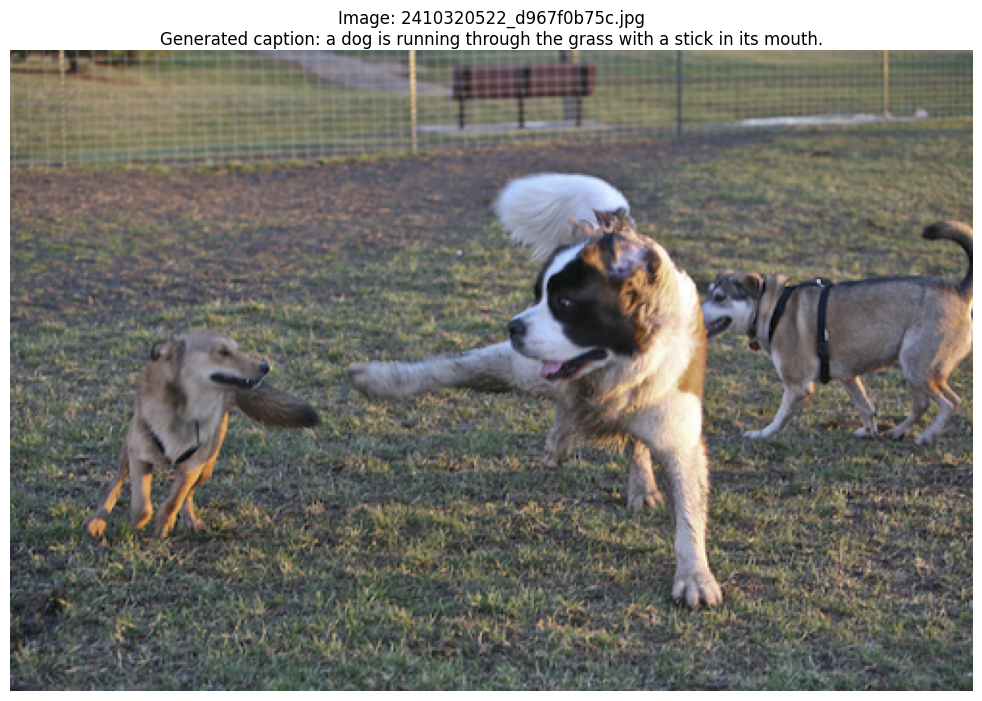

In [54]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

sample_test_name = random.choice(list(test_features.keys()))

sample_generated_caption = generate_transformer_caption(
    test_features[sample_test_name],
    transformer_decoder
)

sample_image_path = os.path.join(IMAGE_DIR, sample_test_name)

with Image.open(sample_image_path) as img:
    plt.figure(figsize=(10, 7))
    plt.imshow(img.convert("RGB"))
    plt.axis("off")
    plt.title(
        f"Image: {sample_test_name}\n"
        f"Generated caption: {sample_generated_caption}",
        fontsize=12,
        wrap=True
    )
    plt.tight_layout()
    plt.show()

In [55]:
# ============================================================
# PHASE 3 — CELL 27
# Compare generated and reference captions
# ============================================================

sample_references = test_caption_mapping[sample_test_name]

print("Image:", sample_test_name)
print("\nGenerated caption:")
print(sample_generated_caption)

print("\nReference captions:")
for i, caption_ids in enumerate(sample_references, start=1):
    words = [
        id_to_word.get(int(token_id), "<UNK>")
        for token_id in caption_ids.tolist()
        if int(token_id) not in (PAD_ID, START_ID, END_ID)
    ]
    print(f"{i}. {' '.join(words)}")

Image: 2410320522_d967f0b75c.jpg

Generated caption:
a dog is running through the grass with a stick in its mouth.

Reference captions:
1. a big dog holds its paw out to keep another dog at bay.
2. a large dog wards off a smaller dog.
3. large dog plays with two smaller dogs on grass.
4. the brown and white great dane plays with two yellow dogs in the grass.
5. two smaller dogs and one larger dog with a puffy white tail are playing in a field.


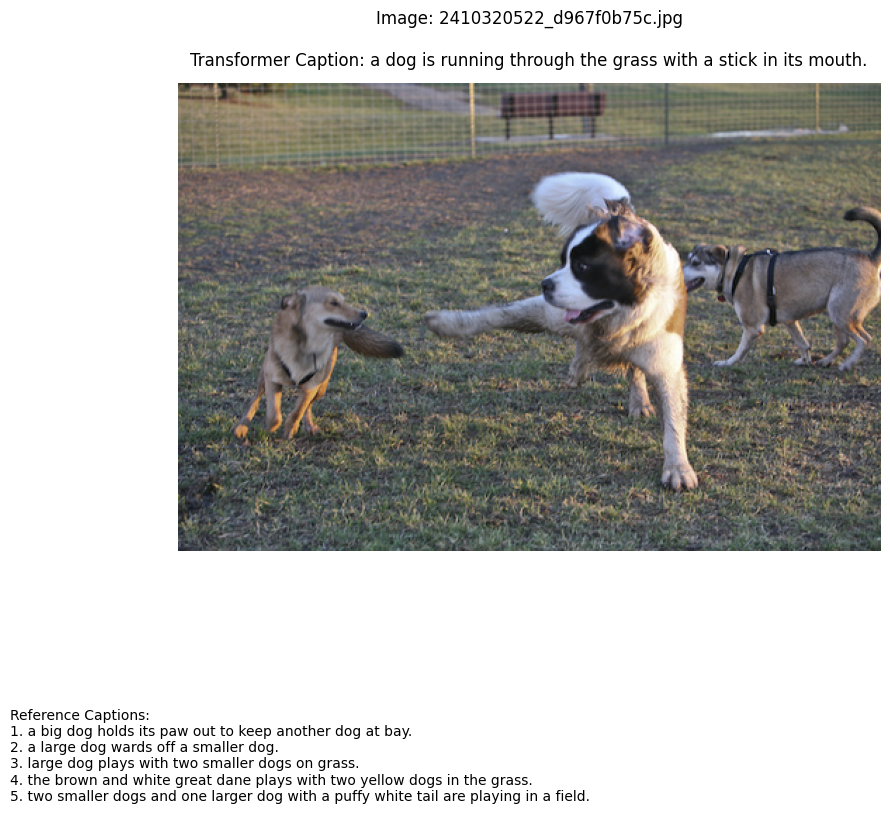

In [56]:
# PHASE 3 — Display image with generated and reference captions

import os
import matplotlib.pyplot as plt
from PIL import Image

sample_image_path = os.path.join(IMAGE_DIR, sample_test_name)

# Decode reference captions
reference_captions = []

for caption_ids in test_caption_mapping[sample_test_name]:
    words = [
        id_to_word.get(int(token_id), "<UNK>")
        for token_id in caption_ids.tolist()
        if int(token_id) not in (PAD_ID, START_ID, END_ID)
    ]
    reference_captions.append(" ".join(words))

# Display image and captions
with Image.open(sample_image_path) as img:
    display_image = img.convert("RGB")

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(display_image)
ax.axis("off")

plt.title(
    f"Image: {sample_test_name}\n\n"
    f"Transformer Caption: {sample_generated_caption}",
    fontsize=12,
    wrap=True,
    pad=15
)

reference_text = "\n".join(
    f"{i}. {caption}" for i, caption in enumerate(reference_captions, start=1)
)

fig.text(
    0.08, 0.02,
    "Reference Captions:\n" + reference_text,
    fontsize=10,
    va="bottom",
    wrap=True
)

plt.subplots_adjust(bottom=0.30, top=0.82)
plt.show()

In [57]:
# PHASE 3 — Generate captions for all test images

import os
import json
import time

transformer_predictions = {}
start_time = time.time()

for i, (image_name, visual_features) in enumerate(test_features.items(), start=1):
    caption = generate_transformer_caption(
        visual_features,
        transformer_decoder
    )
    transformer_predictions[image_name] = caption

    if i % 100 == 0:
        elapsed = (time.time() - start_time) / 60
        print(f"Processed {i}/1000 images | Elapsed: {elapsed:.2f} minutes")

# Save separately — baseline predictions remain unchanged
predictions_path = os.path.join(
    NOTEBOOK_DIR,
    "vit_transformer_predictions.json"
)

with open(predictions_path, "w", encoding="utf-8") as f:
    json.dump(transformer_predictions, f, indent=2, ensure_ascii=False)

print("\nCaption generation completed.")
print("Total images:", len(transformer_predictions))
print("Saved to:", predictions_path)
print(f"Total time: {(time.time() - start_time) / 60:.2f} minutes")

Processed 100/1000 images | Elapsed: 0.16 minutes
Processed 200/1000 images | Elapsed: 0.32 minutes
Processed 300/1000 images | Elapsed: 0.49 minutes
Processed 400/1000 images | Elapsed: 0.67 minutes
Processed 500/1000 images | Elapsed: 0.83 minutes
Processed 600/1000 images | Elapsed: 0.99 minutes
Processed 700/1000 images | Elapsed: 1.15 minutes
Processed 800/1000 images | Elapsed: 1.32 minutes
Processed 900/1000 images | Elapsed: 1.49 minutes
Processed 1000/1000 images | Elapsed: 1.66 minutes

Caption generation completed.
Total images: 1000
Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_transformer_predictions.json
Total time: 1.66 minutes


In [58]:
# PHASE 3 — Check evaluation libraries

import nltk

print("NLTK version:", nltk.__version__)

for package in ["punkt", "wordnet", "omw-1.4"]:
    try:
        nltk.data.find(
            f"tokenizers/{package}"
            if package == "punkt"
            else f"corpora/{package}"
        )
        print(f"{package}: Available")
    except LookupError:
        print(f"{package}: Not found")

NLTK version: 3.10.0
punkt: Available
wordnet: Not found
omw-1.4: Not found


## Inspecting

In [59]:
# Check evaluation libraries

packages = {
    "nltk": "nltk",
    "rouge_score": "rouge_score",
    "evaluate": "evaluate",
    "pycocoevalcap": "pycocoevalcap"
}

for package_name, module_name in packages.items():
    try:
        module = __import__(module_name)
        version = getattr(module, "__version__", "Installed")
        print(f"{package_name}: Available ({version})")
    except ImportError:
        print(f"{package_name}: Not installed")

nltk: Available (3.10.0)
rouge_score: Not installed
evaluate: Not installed
pycocoevalcap: Not installed


In [61]:
# PHASE 3 — Evaluate ViT + Transformer

import os
import json
import nltk
import numpy as np
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score

# Load saved Transformer predictions
predictions_path = os.path.join(
    NOTEBOOK_DIR, "vit_transformer_predictions.json"
)

with open(predictions_path, "r", encoding="utf-8") as f:
    transformer_predictions = json.load(f)

# Decode reference captions
references = {}
for image_name, caption_list in test_caption_mapping.items():
    references[image_name] = []

    for caption_ids in caption_list:
        words = [
            id_to_word.get(int(token_id), "<UNK>")
            for token_id in caption_ids.tolist()
            if int(token_id) not in (PAD_ID, START_ID, END_ID)
        ]
        references[image_name].append(words)

# Prepare metric inputs
all_references = []
all_hypotheses = []
smooth = SmoothingFunction().method1

for image_name, prediction in transformer_predictions.items():
    hypothesis = prediction.lower().split()
    ref_tokens = [ref for ref in references[image_name]]

    all_references.append(ref_tokens)
    all_hypotheses.append(hypothesis)

# BLEU-1 to BLEU-4
weights = {
    "BLEU-1": (1, 0, 0, 0),
    "BLEU-2": (0.5, 0.5, 0, 0),
    "BLEU-3": (1/3, 1/3, 1/3, 0),
    "BLEU-4": (0.25, 0.25, 0.25, 0.25)
}

metrics = {}

for name, weight in weights.items():
    metrics[name] = corpus_bleu(
        all_references,
        all_hypotheses,
        weights=weight,
        smoothing_function=smooth
    )

# METEOR
meteor_scores = []

for refs, hyp in zip(all_references, all_hypotheses):
    try:
        meteor_scores.append(
            meteor_score(refs, hyp)
        )
    except LookupError:
        print("WordNet is missing. METEOR requires WordNet; skipping it for now.")
        meteor_scores = []
        break

if meteor_scores:
    metrics["METEOR"] = float(np.mean(meteor_scores))

# ROUGE-L (F1), implemented directly
def lcs_length(a, b):
    previous = [0] * (len(b) + 1)

    for word_a in a:
        current = [0]
        for j, word_b in enumerate(b, start=1):
            if word_a == word_b:
                current.append(previous[j - 1] + 1)
            else:
                current.append(max(previous[j], current[-1]))
        previous = current

    return previous[-1]

def rouge_l_f1(reference, hypothesis):
    if not reference or not hypothesis:
        return 0.0

    lcs = lcs_length(reference, hypothesis)
    precision = lcs / len(hypothesis)
    recall = lcs / len(reference)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)

rouge_scores = []

for refs, hyp in zip(all_references, all_hypotheses):
    # Best matching reference for each image
    rouge_scores.append(
        max(rouge_l_f1(ref, hyp) for ref in refs)
    )

metrics["ROUGE-L"] = float(np.mean(rouge_scores))

# Display and save Transformer metrics
print("\nViT + Transformer Evaluation")
print("-" * 35)

for name, score in metrics.items():
    print(f"{name}: {score:.4f}")

metrics_path = os.path.join(NOTEBOOK_DIR, "vit_transformer_metrics.json")

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("\nSaved metrics to:", metrics_path)


ViT + Transformer Evaluation
-----------------------------------
BLEU-1: 0.5241
BLEU-2: 0.3615
BLEU-3: 0.2409
BLEU-4: 0.1583
METEOR: 0.4055
ROUGE-L: 0.4149

Saved metrics to: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_transformer_metrics.json


In [63]:
import json
from pathlib import Path

phase3_path = Path.cwd() / "Phase3_ViT_Transformer.ipynb"
nb = json.loads(phase3_path.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if "class TransformerCaptionDecoder" in source:
        print(f"Found decoder in notebook cell {i + 1}\n")
        print(source)
        break
else:
    print("Decoder class not found.")

Found decoder in notebook cell 29

# ============================================================
# PHASE 3 — CELL 16
# Define Transformer Caption Decoder
# ============================================================

import torch
import torch.nn as nn
import math

class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        visual_dim=768,
        embed_dim=256,
        num_heads=8,
        num_layers=3,
        feedforward_dim=1024,
        max_length=38,
        dropout=0.1
    ):
        super().__init__()

        self.embed_dim = embed_dim
        self.max_length = max_length

        # Convert token IDs into word embeddings
        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )

        # Project visual patch features into decoder dimension
        self.visual_projection = nn.Linear(
            visual_dim, embed_dim
        )

        # Learnable positional embeddings for caption tokens
     

In [64]:
import json
from pathlib import Path

phase3_path = Path.cwd() / "Phase3_ViT_Transformer.ipynb"
nb = json.loads(phase3_path.read_text(encoding="utf-8"))

keywords = [
    "vocab",
    "idx_to_word",
    "word_to_idx",
    "load_state_dict",
    "best_vit_transformer",
    "vit_transformer_predictions",
    "generate_caption",
    "class VisionTransformer",
    "class ViT"
]

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matched = [word for word in keywords if word.lower() in source.lower()]

    if matched:
        print(f"\n--- Cell {i + 1} | Matches: {', '.join(matched)} ---")
        print(source[:1800])


--- Cell 1 | Matches: vocab ---
# ============================================================
# PHASE 3 — ADVANCED MODEL
# Cell 1: Environment & Existing Artifact Verification
# ============================================================

import os
import json
import torch
import torchvision

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_DIR = r"C:\Users\rajva\Desktop\image-captioning Project"
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebook")

CHECKPOINT_DIR = os.path.join(NOTEBOOK_DIR, "checkpoints")
FEATURE_DIR = os.path.join(NOTEBOOK_DIR, "cached_features")

print("Project directory:")
print(PROJECT_DIR)

print("\nNotebook directory:")
print(NOTEBOOK_DIR)


# ------------------------------------------------------------
# 2. CPU verification
# ------------------------------------------------------------

device = torch.device("cpu")

print("\nDevice:", device)
print("CUDA

## Retesting

In [1]:
import json
from pathlib import Path

notebook_path = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
    r"\notebook\Phase3_ViT_Transformer.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = [
    "CrossEntropyLoss",
    "optimizer.step",
    "train_loader",
    "caption_ids",
    "best_vit_transformer",
    "NUM_EPOCHS",
    "model_state_dict",
    "token_ids",
]

for i, cell in enumerate(notebook_data["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(word in source for word in keywords):
        print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
        print(source[:4500])
        if len(source) > 4500:
            print("\n... [remaining code omitted]")


========================= CELL 25 =========================
# ============================================================
# PHASE 3 — CELL 14
# Verify vocabulary and caption token sequences
# ============================================================

import os
import json

vocab_path = os.path.join(NOTEBOOK_DIR, "vocabulary.json")

with open(vocab_path, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

print("Vocabulary JSON type:", type(vocab_data).__name__)

if isinstance(vocab_data, dict):
    print("Vocabulary size:", len(vocab_data))

    # Display special tokens if stored as token -> ID
    for token in ["<PAD>", "<START>", "<END>", "<UNK>"]:
        print(f"{token}: {vocab_data.get(token, 'NOT FOUND')}")

    # Display a sample caption
    sample_row = captions_df.iloc[0]
    print("\nSample image:", sample_row["image"])
    print("Sample caption:", sample_row["caption"])
    print("Token IDs:", sample_row["token_ids"])
    print("Padded IDs:", sample_row["padded_

In [2]:
# Read-only check of the Phase 3 training history

try:
    print("Epoch | Training Loss | Validation Loss")
    print("-" * 43)

    for row in training_history:
        print(
            f"{row['epoch']:5} | "
            f"{row['train_loss']:13.4f} | "
            f"{row['val_loss']:15.4f}"
        )

except NameError:
    print("training_history is not available in the current kernel.")
    print("We will inspect the saved notebook outputs instead.")

Epoch | Training Loss | Validation Loss
-------------------------------------------
training_history is not available in the current kernel.
We will inspect the saved notebook outputs instead.


In [3]:
import json
from pathlib import Path
import torch

project_dir = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
)
notebook_path = project_dir / "notebook" / "Phase3_ViT_Transformer.ipynb"
checkpoint_path = (
    project_dir / "notebook" / "checkpoints_vit_transformer"
    / "best_vit_transformer.pth"
)

# 1. Inspect saved training logs
with notebook_path.open("r", encoding="utf-8") as f:
    nb = json.load(f)

print("=== SAVED TRAINING OUTPUTS ===")

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if "for epoch in range" in source and "run_epoch" in source:
        print(f"\n--- Training cell index {i} ---")

        for output in cell.get("outputs", []):
            text_output = "".join(
                output.get("text", [])
            )

            if text_output:
                print(text_output[-12000:])

            for data in output.get("data", {}).values():
                if isinstance(data, dict):
                    continue

                if isinstance(data, list):
                    print("".join(str(x) for x in data)[-12000:])

# 2. Inspect checkpoint metadata
print("\n=== SAVED CHECKPOINT ===")

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint epoch:", checkpoint.get("epoch"))
    print("Validation loss:", checkpoint.get("val_loss"))
    print("Vocabulary size:", checkpoint.get("vocab_size"))
    print("Checkpoint exists:", True)
else:
    print("Checkpoint not found:", checkpoint_path)

=== SAVED TRAINING OUTPUTS ===

--- Training cell index 39 ---

Epoch 1/1
Train batch 250/3750 | loss=5.3903 | elapsed=1.2 min
Train batch 500/3750 | loss=5.0869 | elapsed=2.4 min
Train batch 750/3750 | loss=4.2866 | elapsed=3.6 min
Train batch 1000/3750 | loss=4.4271 | elapsed=4.7 min
Train batch 1250/3750 | loss=4.2833 | elapsed=5.9 min
Train batch 1500/3750 | loss=4.3223 | elapsed=7.1 min
Train batch 1750/3750 | loss=4.0841 | elapsed=8.4 min
Train batch 2000/3750 | loss=4.7041 | elapsed=9.6 min
Train batch 2250/3750 | loss=4.4518 | elapsed=10.8 min
Train batch 2500/3750 | loss=3.5005 | elapsed=12.0 min
Train batch 2750/3750 | loss=3.1720 | elapsed=13.3 min
Train batch 3000/3750 | loss=3.7718 | elapsed=14.5 min
Train batch 3250/3750 | loss=4.3342 | elapsed=15.8 min
Train batch 3500/3750 | loss=3.3766 | elapsed=17.0 min
Train batch 3750/3750 | loss=3.9867 | elapsed=18.3 min
Val batch 250/625 | loss=2.4910 | elapsed=0.2 min
Val batch 500/625 | loss=3.4978 | elapsed=0.4 min

Train loss:

In [1]:
from pathlib import Path
import shutil
import torch

notebook_dir = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project\notebook"
)

original_checkpoint = (
    notebook_dir
    / "checkpoints_vit_transformer"
    / "best_vit_transformer.pth"
)

experiment_dir = notebook_dir / "checkpoints_vit_experiment"
experiment_dir.mkdir(parents=True, exist_ok=True)

experiment_checkpoint = (
    experiment_dir / "vit_transformer_experiment.pth"
)

assert original_checkpoint.exists(), (
    f"Original checkpoint not found: {original_checkpoint}"
)

shutil.copy2(original_checkpoint, experiment_checkpoint)

checkpoint = torch.load(
    experiment_checkpoint,
    map_location="cpu",
    weights_only=True,
)

print("Original checkpoint preserved:", original_checkpoint.exists())
print("Experimental checkpoint created:", experiment_checkpoint.exists())
print("Starting epoch:", checkpoint["epoch"])
print("Starting validation loss:", round(checkpoint["val_loss"], 4))
print("Original checkpoint was not modified.")

Original checkpoint preserved: True
Experimental checkpoint created: True
Starting epoch: 4
Starting validation loss: 3.2314
Original checkpoint was not modified.


In [2]:
required_vars = [
    "decoder",
    "optimizer",
    "train_loader",
    "val_loader",
    "device",
]

for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

decoder: Missing
optimizer: Missing
train_loader: Missing
val_loader: Missing
device: Missing


In [3]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
)
notebook_dir = project_dir / "notebook"

paths_to_check = {
    "Project directory": project_dir,
    "Notebook directory": notebook_dir,
    "Vocabulary": notebook_dir / "vocabulary.json",
    "Training features": notebook_dir / "vit_cached_features" / "train_vit_features.pt",
    "Validation features": notebook_dir / "vit_cached_features" / "val_vit_features.pt",
    "Test features": notebook_dir / "vit_cached_features" / "test_vit_features.pt",
    "Experimental checkpoint": notebook_dir / "checkpoints_vit_experiment" / "vit_transformer_experiment.pth",
}

for name, path in paths_to_check.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

Project directory: FOUND
Notebook directory: FOUND
Vocabulary: FOUND
Training features: FOUND
Validation features: FOUND
Test features: FOUND
Experimental checkpoint: FOUND


In [9]:
import json
from pathlib import Path

notebook_path = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
    r"\notebook\Phase3_ViT_Transformer.ipynb"
)

nb = json.loads(notebook_path.read_text(encoding="utf-8"))

keywords = [
    "Dataset",
    "DataLoader",
    "train_caption_mapping",
    "val_caption_mapping",
    "AdamW",
    "CrossEntropyLoss",
    "optimizer",
    "additional_epochs",
    "VIT_BEST_CHECKPOINT",
    "for epoch in range",
]

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matched = [word for word in keywords if word in source]

    if matched:
        print(f"\n{'=' * 70}")
        print(f"NOTEBOOK CELL {i + 1} | Matches: {', '.join(matched)}")
        print("=" * 70)
        print(source)


NOTEBOOK CELL 12 | Matches: Dataset
# ============================================================
# PHASE 3 — CELL 7
# Inspect saved caption dataset and image paths
# ============================================================

import os
import pandas as pd

captions_path = os.path.join(NOTEBOOK_DIR, "processed_captions.pkl")

captions_df = pd.read_pickle(captions_path)

print("Dataset shape:", captions_df.shape)
print("\nColumns:")
print(captions_df.columns.tolist())

print("\nSplit distribution:")
print(captions_df["split"].value_counts())

print("\nUnique images per split:")
print(captions_df.groupby("split")["image"].nunique())

print("\nSample image filenames:")
print(captions_df[["image", "split", "caption"]].head(5).to_string(index=False))

print("\nCaption dataset loaded successfully.")

NOTEBOOK CELL 35 | Matches: val_caption_mapping

# PHASE 3 — CELL 18
# Load validation/test features and build caption mappings

import os
import torch

# Load smaller validation and test ca

In [10]:

from pathlib import Path
import json
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Paths and device
# --------------------------------------------------
PROJECT_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project"
)
NOTEBOOK_DIR = PROJECT_DIR / "notebook"
VIT_FEATURE_DIR = NOTEBOOK_DIR / "vit_cached_features"

device = torch.device("cpu")

# --------------------------------------------------
# 2. Load existing captions and vocabulary
# --------------------------------------------------
captions_df = pd.read_pickle(
    NOTEBOOK_DIR / "processed_captions.pkl"
)

with open(
    NOTEBOOK_DIR / "vocabulary.json",
    "r",
    encoding="utf-8"
) as f:
    vocabulary = json.load(f)

assert isinstance(vocabulary, dict), (
    "Expected vocabulary.json to contain a token-to-ID dictionary."
)

VOCAB_SIZE = len(vocabulary)

assert vocabulary.get("<PAD>") == 0
assert vocabulary.get("<START>") == 1
assert vocabulary.get("<END>") == 2

print("Vocabulary size:", VOCAB_SIZE)
print("Caption dataset:", captions_df.shape)
print("Split counts:")
print(captions_df["split"].value_counts())

# --------------------------------------------------
# 3. Load existing feature caches (no extraction)
# --------------------------------------------------
train_features = torch.load(
    VIT_FEATURE_DIR / "train_vit_features.pt",
    map_location="cpu",
    weights_only=True,
    mmap=True
)

val_features = torch.load(
    VIT_FEATURE_DIR / "val_vit_features.pt",
    map_location="cpu",
    weights_only=True,
    mmap=True
)

print("Training feature images:", len(train_features))
print("Validation feature images:", len(val_features))

# --------------------------------------------------
# 4. Rebuild image-to-caption mappings
# --------------------------------------------------
def build_caption_mapping(dataframe, split_name):
    split_df = dataframe[dataframe["split"] == split_name]
    mapping = {}

    for image_name, group in split_df.groupby(
        "image", sort=False
    ):
        mapping[image_name] = [
            torch.as_tensor(ids, dtype=torch.long)
            for ids in group["token_ids"]
        ]

    return mapping


train_caption_mapping = build_caption_mapping(
    captions_df, "train"
)
val_caption_mapping = build_caption_mapping(
    captions_df, "validation"
)

assert set(train_features) == set(train_caption_mapping)
assert set(val_features) == set(val_caption_mapping)

# --------------------------------------------------
# 5. Rebuild the original datasets and DataLoaders
# --------------------------------------------------
class CaptionFeatureDataset(Dataset):
    def __init__(self, features, caption_mapping):
        self.features = features
        self.samples = []

        for image_name, captions in caption_mapping.items():
            for caption_ids in captions:
                self.samples.append((image_name, caption_ids))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_name, caption_ids = self.samples[index]
        visual_features = self.features[image_name].float()

        caption_ids = caption_ids.long()
        return (
            visual_features,
            caption_ids[:-1],
            caption_ids[1:]
        )


def collate_caption_batch(batch):
    visual, inputs, targets = zip(*batch)

    visual = torch.stack(visual)
    inputs = nn.utils.rnn.pad_sequence(
        inputs, batch_first=True, padding_value=0
    )
    targets = nn.utils.rnn.pad_sequence(
        targets, batch_first=True, padding_value=0
    )

    return visual, inputs, targets


BATCH_SIZE = 8

train_dataset = CaptionFeatureDataset(
    train_features, train_caption_mapping
)
val_dataset = CaptionFeatureDataset(
    val_features, val_caption_mapping
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_caption_batch,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_caption_batch,
    num_workers=0
)

# --------------------------------------------------
# 6. Recreate the original decoder and optimizer
# --------------------------------------------------
transformer_decoder = TransformerCaptionDecoder(
    vocab_size=VOCAB_SIZE,
    visual_dim=768,
    embed_dim=256,
    num_heads=8,
    num_layers=3,
    feedforward_dim=1024,
    max_length=38,
    dropout=0.1
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=0)

optimizer = optim.AdamW(
    transformer_decoder.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

GRAD_CLIP = 1.0

# --------------------------------------------------
# 7. Restore the EXPERIMENTAL checkpoint only
# --------------------------------------------------
EXPERIMENT_CHECKPOINT = (
    NOTEBOOK_DIR
    / "checkpoints_vit_experiment"
    / "vit_transformer_experiment.pth"
)

checkpoint = torch.load(
    EXPERIMENT_CHECKPOINT,
    map_location=device,
    weights_only=True
)

assert checkpoint["vocab_size"] == VOCAB_SIZE, (
    "Vocabulary size mismatch. Stop without training."
)

transformer_decoder.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

best_val_loss = checkpoint["val_loss"]
start_epoch = checkpoint["epoch"] + 1

# This is a new experiment; the original training history
# remains saved in the original notebook outputs.
training_history = []

print("\n--- EXPERIMENT READY ---")
print("Checkpoint loaded:", EXPERIMENT_CHECKPOINT)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Starting epoch:", start_epoch)
print("Starting validation loss:", round(best_val_loss, 4))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches per epoch:", len(train_loader))
print("Validation batches per epoch:", len(val_loader))
print("Optimizer learning rate:",
      optimizer.param_groups[0]["lr"])
print("Original checkpoint remains untouched.")


Vocabulary size: 12076
Caption dataset: (40000, 9)
Split counts:
split
train         30000
validation     5000
test           5000
Name: count, dtype: int64
Training feature images: 6000
Validation feature images: 1000

--- EXPERIMENT READY ---
Checkpoint loaded: C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints_vit_experiment\vit_transformer_experiment.pth
Checkpoint epoch: 4
Starting epoch: 5
Starting validation loss: 3.2314
Training samples: 30000
Validation samples: 5000
Training batches per epoch: 3750
Validation batches per epoch: 625
Optimizer learning rate: 0.0001
Original checkpoint remains untouched.


In [13]:

import time
import torch

def run_epoch(model, loader, training=True):
    model.train() if training else model.eval()

    total_loss = 0.0
    total_tokens = 0
    start_time = time.time()

    for batch_idx, (visual, captions_in, captions_out) in enumerate(loader):
        visual = visual.to(device)
        captions_in = captions_in.to(device)
        captions_out = captions_out.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(visual, captions_in)

            loss = criterion(
                logits.transpose(1, 2),
                captions_out
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), GRAD_CLIP
                )
                optimizer.step()

        valid_tokens = captions_out.ne(0).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        if (batch_idx + 1) % 250 == 0:
            elapsed = (time.time() - start_time) / 60
            print(
                f"{'Train' if training else 'Val'} "
                f"batch {batch_idx + 1}/{len(loader)} | "
                f"loss={loss.item():.4f} | "
                f"elapsed={elapsed:.1f} min"
            )

    average_loss = total_loss / max(total_tokens, 1)
    elapsed = (time.time() - start_time) / 60

    return average_loss, elapsed

print("run_epoch() defined successfully.")


run_epoch() defined successfully.


In [14]:

import torch
from pathlib import Path

EXPERIMENT_CHECKPOINT = (
    Path(r"C:\Users\rajva\Desktop\image-captioning Project")
    / "notebook"
    / "checkpoints_vit_experiment"
    / "vit_transformer_experiment.pth"
)

additional_epochs = 2
start_epoch = checkpoint["epoch"] + 1
end_epoch = start_epoch + additional_epochs - 1

for epoch in range(start_epoch, end_epoch + 1):
    print(f"\n{'=' * 15} Epoch {epoch}/{end_epoch} {'=' * 15}")

    train_loss, train_minutes = run_epoch(
        transformer_decoder, train_loader, training=True
    )

    val_loss, val_minutes = run_epoch(
        transformer_decoder, val_loader, training=False
    )

    print(f"\nTrain loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Training time: {train_minutes:.2f} min")
    print(f"Validation time: {val_minutes:.2f} min")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch,
            "model_state_dict": transformer_decoder.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "vocab_size": VOCAB_SIZE
        }, EXPERIMENT_CHECKPOINT)

        print("Improved experimental checkpoint saved.")
    else:
        print("No validation improvement; experimental best preserved.")

    print(f"Best experimental validation loss: {best_val_loss:.4f}")

print("\nExperimental training finished.")
print("Experimental checkpoint:", EXPERIMENT_CHECKPOINT)
print("Best validation loss:", round(best_val_loss, 4))
print("Original Phase 3 checkpoint remains untouched.")



=============== Epoch 5/6 ===============
Train batch 250/3750 | loss=2.3978 | elapsed=5.9 min
Train batch 500/3750 | loss=3.1051 | elapsed=11.6 min
Train batch 750/3750 | loss=2.7957 | elapsed=14.8 min
Train batch 1000/3750 | loss=2.7471 | elapsed=17.7 min
Train batch 1250/3750 | loss=3.0769 | elapsed=20.5 min
Train batch 1500/3750 | loss=2.0068 | elapsed=24.3 min
Train batch 1750/3750 | loss=2.4668 | elapsed=27.2 min
Train batch 2000/3750 | loss=3.0217 | elapsed=28.9 min
Train batch 2250/3750 | loss=2.2345 | elapsed=30.2 min
Train batch 2500/3750 | loss=2.2726 | elapsed=31.4 min
Train batch 2750/3750 | loss=2.8366 | elapsed=32.7 min
Train batch 3000/3750 | loss=3.0390 | elapsed=33.9 min
Train batch 3250/3750 | loss=2.0875 | elapsed=35.1 min
Train batch 3500/3750 | loss=2.3997 | elapsed=36.6 min
Train batch 3750/3750 | loss=2.5639 | elapsed=37.9 min
Val batch 250/625 | loss=2.0260 | elapsed=0.2 min
Val batch 500/625 | loss=3.0547 | elapsed=0.4 min

Train loss: 2.6308
Validation loss:

In [15]:
import torch
from pathlib import Path

EXPERIMENT_CHECKPOINT = (
    Path(r"C:\Users\rajva\Desktop\image-captioning Project")
    / "notebook"
    / "checkpoints_vit_experiment"
    / "vit_transformer_experiment.pth"
)

checkpoint_exp = torch.load(
    EXPERIMENT_CHECKPOINT,
    map_location=device,
    weights_only=True
)

transformer_decoder.load_state_dict(
    checkpoint_exp["model_state_dict"]
)
transformer_decoder.eval()

print("Experimental model loaded successfully.")
print("Best epoch:", checkpoint_exp["epoch"])
print("Best validation loss:", checkpoint_exp["val_loss"])
print("Original Phase 3 checkpoint remains unchanged.")

Experimental model loaded successfully.
Best epoch: 6
Best validation loss: 3.198484966344772
Original Phase 3 checkpoint remains unchanged.


In [16]:
import torch
from pathlib import Path

NOTEBOOK_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project\notebook"
)

ORIGINAL_CHECKPOINT = (
    NOTEBOOK_DIR
    / "checkpoints_vit_transformer"
    / "best_vit_transformer.pth"
)

EXPERIMENT_CHECKPOINT = (
    NOTEBOOK_DIR
    / "checkpoints_vit_experiment"
    / "vit_transformer_experiment.pth"
)

# Save the current experimental weights in memory
experimental_state = {
    key: value.detach().cpu().clone()
    for key, value in transformer_decoder.state_dict().items()
}

# Load original Phase 3 model weights
original_ckpt = torch.load(
    ORIGINAL_CHECKPOINT,
    map_location=device,
    weights_only=True
)
transformer_decoder.load_state_dict(
    original_ckpt["model_state_dict"]
)
transformer_decoder.eval()

print("Original Phase 3 weights loaded for comparison.")
print("Original epoch:", original_ckpt["epoch"])

Original Phase 3 weights loaded for comparison.
Original epoch: 4


In [17]:
[name for name, obj in globals().copy().items()
 if callable(obj) and any(
     word in name.lower()
     for word in ["generate_caption", "greedy_decode", "decode_caption"]
 )]

[]

In [18]:
import torch

# Create ID-to-word mapping from your existing vocabulary
id_to_word = {idx: word for word, idx in vocab_data.items()}

PAD_ID = vocab_data["<PAD>"]
START_ID = vocab_data["<START>"]
END_ID = vocab_data["<END>"]
MAX_LENGTH = 38

def generate_caption_from_features(model, visual_features):
    model.eval()

    if visual_features.dim() == 2:
        visual_features = visual_features.unsqueeze(0)

    visual_features = visual_features.to(device).float()
    caption_ids = [START_ID]

    with torch.no_grad():
        for _ in range(MAX_LENGTH - 1):
            input_ids = torch.tensor(
                [caption_ids],
                dtype=torch.long,
                device=device
            )

            logits = model(visual_features, input_ids)
            next_id = logits[0, -1].argmax(dim=-1).item()

            if next_id in (END_ID, PAD_ID):
                break

            caption_ids.append(next_id)

    words = [
        id_to_word[token_id]
        for token_id in caption_ids[1:]
        if token_id in id_to_word
    ]

    return " ".join(words)

print("Caption-generation function defined.")
print("Vocabulary mapping size:", len(id_to_word))

Caption-generation function defined.
Vocabulary mapping size: 12076


In [14]:
required = [
    "vocab_data",
    "device",
    "transformer_decoder",
    "test_features",
    "experimental_state",
    "generate_caption_from_features",
    "ORIGINAL_CHECKPOINT",
    "EXPERIMENT_CHECKPOINT",
]

for name in required:
    print(f"{name}: {'OK' if name in globals() else 'MISSING'}")

vocab_data: MISSING
device: MISSING
transformer_decoder: MISSING
test_features: OK
experimental_state: MISSING
generate_caption_from_features: MISSING
ORIGINAL_CHECKPOINT: MISSING
EXPERIMENT_CHECKPOINT: MISSING


In [16]:
import json
import math
import torch
import torch.nn as nn
from pathlib import Path

# 1. Paths and device
NOTEBOOK_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project\notebook"
)
ORIGINAL_CHECKPOINT = (
    NOTEBOOK_DIR / "checkpoints_vit_transformer"
    / "best_vit_transformer.pth"
)
EXPERIMENT_CHECKPOINT = (
    NOTEBOOK_DIR / "checkpoints_vit_experiment"
    / "vit_transformer_experiment.pth"
)
VOCAB_PATH = NOTEBOOK_DIR / "vocabulary.json"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Vocabulary
with open(VOCAB_PATH, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

VOCAB_SIZE = len(vocab_data)
id_to_word = {idx: word for word, idx in vocab_data.items()}
PAD_ID = vocab_data["<PAD>"]
START_ID = vocab_data["<START>"]
END_ID = vocab_data["<END>"]
MAX_LENGTH = 38

# 3. Decoder definition — same architecture as Phase 3
class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self, vocab_size, visual_dim=768, embed_dim=256,
        num_heads=8, num_layers=3, feedforward_dim=1024,
        max_length=38, dropout=0.1
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.position_embedding = nn.Embedding(max_length, embed_dim)
        self.visual_projection = nn.Linear(visual_dim, embed_dim)
        layer = nn.TransformerDecoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True
        )
        self.transformer_decoder = nn.TransformerDecoder(
            layer, num_layers=num_layers
        )
        self.output_layer = nn.Linear(embed_dim, vocab_size)
        self.embed_scale = math.sqrt(embed_dim)
        self.max_length = max_length

    def forward(self, visual_features, caption_ids):
        batch_size, seq_len = caption_ids.shape
        positions = torch.arange(
            seq_len, device=caption_ids.device
        ).unsqueeze(0).expand(batch_size, -1)

        tgt = self.embedding(caption_ids) * self.embed_scale
        tgt = tgt + self.position_embedding(positions)
        memory = self.visual_projection(visual_features)

        causal_mask = torch.triu(
            torch.ones(
                seq_len, seq_len, dtype=torch.bool,
                device=caption_ids.device
            ),
            diagonal=1
        )
        padding_mask = caption_ids.eq(0)

        decoded = self.transformer_decoder(
            tgt=tgt,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=padding_mask
        )
        return self.output_layer(decoded)

# 4. Load both checkpoints
original_ckpt = torch.load(
    ORIGINAL_CHECKPOINT, map_location=device, weights_only=True
)
experimental_ckpt = torch.load(
    EXPERIMENT_CHECKPOINT, map_location=device, weights_only=True
)

transformer_decoder = TransformerCaptionDecoder(
    vocab_size=VOCAB_SIZE
).to(device)

# Save experimental weights in memory, then restore original for baseline
experimental_state = {
    k: v.clone() for k, v in
    experimental_ckpt["model_state_dict"].items()
}
transformer_decoder.load_state_dict(
    original_ckpt["model_state_dict"]
)
transformer_decoder.eval()

# 5. Caption generation
def generate_caption_from_features(model, visual_features):
    model.eval()
    if visual_features.dim() == 2:
        visual_features = visual_features.unsqueeze(0)
    visual_features = visual_features.to(device).float()
    generated = [START_ID]

    with torch.no_grad():
        for _ in range(MAX_LENGTH - 1):
            ids = torch.tensor([generated], dtype=torch.long, device=device)
            logits = model(visual_features, ids)
            next_id = logits[0, -1].argmax(dim=-1).item()
            if next_id in (END_ID, PAD_ID):
                break
            generated.append(next_id)

    return " ".join(
        id_to_word[token_id]
        for token_id in generated[1:]
        if token_id in id_to_word
    )

print("Recovery successful.")
print("Device:", device)
print("Vocabulary size:", VOCAB_SIZE)
print("Test images:", len(test_features))
print("Original checkpoint epoch:", original_ckpt["epoch"])
print("Experimental checkpoint epoch:", experimental_ckpt["epoch"])
print("Both checkpoints loaded; neither file was modified.")

Recovery successful.
Device: cpu
Vocabulary size: 12076
Test images: 1000
Original checkpoint epoch: 4
Experimental checkpoint epoch: 6
Both checkpoints loaded; neither file was modified.


In [17]:
preferred_image = "1096395242_fc69f0ae5a.jpg"

sample_names = []
if preferred_image in test_features:
    sample_names.append(preferred_image)

sample_names.extend(
    name for name in sorted(test_features.keys())
    if name not in sample_names
)
sample_names = sample_names[:5]

# Generate captions using original Phase 3 weights
transformer_decoder.load_state_dict(
    original_ckpt["model_state_dict"]
)
transformer_decoder.eval()

original_captions = {
    name: generate_caption_from_features(
        transformer_decoder, test_features[name]
    )
    for name in sample_names
}

# Generate captions using experimental epoch 6 weights
transformer_decoder.load_state_dict(experimental_state)
transformer_decoder.eval()

experimental_captions = {
    name: generate_caption_from_features(
        transformer_decoder, test_features[name]
    )
    for name in sample_names
}

# Display results
for i, name in enumerate(sample_names, 1):
    print(f"\n{'=' * 60}")
    print(f"Image {i}: {name}")
    print("Original     :", original_captions[name])
    print("Experimental :", experimental_captions[name])

# Restore original model in memory when finished
transformer_decoder.load_state_dict(
    original_ckpt["model_state_dict"]
)
transformer_decoder.eval()

print("\nComparison complete. Original model restored in memory.")


Image 1: 1096395242_fc69f0ae5a.jpg
Original     : a boy in a red shirt is playing with a toy on a chair in the floor.
Experimental : a little boy in orange shorts is holding a baby in a chair and holding a baby with his mouth.

Image 2: 1056338697_4f7d7ce270.jpg
Original     : a girl in a blue shirt is jumping into the air.
Experimental : a girl in a blue shirt is jumping in a parking lot.

Image 3: 106490881_5a2dd9b7bd.jpg
Original     : a boy in a blue shirt is running in the ocean.
Experimental : a young boy wearing a black and white shirt is running on the beach.

Image 4: 1082379191_ec1e53f996.jpg
Original     : a man sitting on a bench in the middle of a boat on a lake.
Experimental : a man and a woman sit on a bench in the middle of a lake.

Image 5: 1084040636_97d9633581.jpg
Original     : a white dog is standing in the water with a stick in its mouth.
Experimental : a white dog is standing in the water.

Comparison complete. Original model restored in memory.


In [18]:
import importlib.util

for package in ["nltk", "rouge_score"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

nltk: Installed
rouge_score: Not installed


In [7]:
from pathlib import Path
import torch

NOTEBOOK_DIR = Path(
    r"C:\Users\rajva\Desktop\image-captioning Project\notebook"
)

TEST_FEATURE_PATH = (
    NOTEBOOK_DIR / "vit_cached_features" / "test_vit_features.pt"
)

assert TEST_FEATURE_PATH.exists(), (
    f"Test feature cache not found: {TEST_FEATURE_PATH}"
)

test_features = torch.load(
    TEST_FEATURE_PATH,
    map_location="cpu",
    weights_only=True
)

print("Test features loaded successfully.")
print("Number of test images:", len(test_features))
print("Example image:", next(iter(test_features)))

Test features loaded successfully.
Number of test images: 1000
Example image: 1056338697_4f7d7ce270.jpg


In [19]:
import torch

id_to_word = {idx: word for word, idx in vocab_data.items()}

PAD_ID = vocab_data["<PAD>"]
START_ID = vocab_data["<START>"]
END_ID = vocab_data["<END>"]
MAX_LENGTH = 38

def generate_caption_from_features(model, visual_features):
    model.eval()

    if visual_features.dim() == 2:
        visual_features = visual_features.unsqueeze(0)

    visual_features = visual_features.to(device).float()
    caption_ids = [START_ID]

    with torch.no_grad():
        for _ in range(MAX_LENGTH - 1):
            input_ids = torch.tensor(
                [caption_ids],
                dtype=torch.long,
                device=device
            )

            logits = model(visual_features, input_ids)
            next_id = logits[0, -1].argmax(dim=-1).item()

            if next_id in (END_ID, PAD_ID):
                break

            caption_ids.append(next_id)

    return " ".join(
        id_to_word[token_id]
        for token_id in caption_ids[1:]
        if token_id in id_to_word
    )

print("Caption-generation function restored.")

Caption-generation function restored.


In [20]:
[name for name, obj in globals().copy().items()
 if callable(obj) and any(
     word in name.lower()
     for word in ["bleu", "meteor", "rouge", "evaluate"]
 )]

[]

In [22]:
import pandas as pd
from pathlib import Path

CAPTIONS_PATH = (
    Path(r"C:\Users\rajva\Desktop\image-captioning Project")
    / "notebook"
    / "processed_captions.pkl"
)

captions_df = pd.read_pickle(CAPTIONS_PATH)

print("Dataset shape:", captions_df.shape)
print("Columns:", captions_df.columns.tolist())
print("\nSplit counts:")
print(captions_df["split"].value_counts())

print("\nSample test rows:")
display(
    captions_df[captions_df["split"] == "test"][
        ["image", "caption", "clean_caption"]
    ].head()
)

Dataset shape: (40000, 9)
Columns: ['image', 'caption', 'split', 'clean_caption', 'tokens', 'tokens_with_special', 'token_ids', 'caption_length', 'padded_ids']

Split counts:
split
train         30000
validation     5000
test           5000
Name: count, dtype: int64

Sample test rows:


,image,caption,clean_caption
210,1056338697_4f7d7ce270.jpg,A blond woman in a blue shirt appears to wait ...,a blond woman in a blue shirt appears to wait ...
211,1056338697_4f7d7ce270.jpg,A blond woman is on the street hailing a taxi .,a blond woman is on the street hailing a taxi.
212,1056338697_4f7d7ce270.jpg,"A woman is signaling is to traffic , as seen f...","a woman is signaling is to traffic, as seen fr..."
213,1056338697_4f7d7ce270.jpg,A woman with blonde hair wearing a blue tube t...,a woman with blonde hair wearing a blue tube t...
214,1056338697_4f7d7ce270.jpg,The woman in the blue dress is holding out her...,the woman in the blue dress is holding out her...


In [23]:
import time
import json
import numpy as np
import pandas as pd
from pathlib import Path
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score

# Output folder kept separate from completed Phase 3–6 results
OUTPUT_DIR = NOTEBOOK_DIR / "experimental_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Build five reference captions for each test image
test_df = captions_df[captions_df["split"] == "test"].copy()

reference_map = (
    test_df.groupby("image")["clean_caption"]
    .apply(lambda s: [str(c).lower().split() for c in s])
    .to_dict()
)

image_names = sorted(
    name for name in reference_map if name in test_features
)

print("Test images to evaluate:", len(image_names))
print("Reference captions per image:",
      len(reference_map[image_names[0]]))

def rouge_l_f1(reference, hypothesis):
    # Longest common subsequence, using a compact dynamic-programming row
    previous = [0] * (len(hypothesis) + 1)
    for word in reference:
        current = [0]
        for j, hyp_word in enumerate(hypothesis, 1):
            if word == hyp_word:
                current.append(previous[j - 1] + 1)
            else:
                current.append(max(previous[j], current[-1]))
        previous = current

    lcs = previous[-1]
    if not reference or not hypothesis:
        return 0.0

    precision = lcs / len(hypothesis)
    recall = lcs / len(reference)
    return (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

def evaluate_predictions(predictions):
    refs = [
        reference_map[name] for name in image_names
    ]
    hyps = [
        predictions[name].lower().split() for name in image_names
    ]

    smoothing = SmoothingFunction().method1
    scores = {}

    for n, label in enumerate(
        ["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"], start=1
    ):
        weights = tuple(
            1 / n if i < n else 0
            for i in range(4)
        )
        scores[label] = corpus_bleu(
            refs, hyps, weights=weights,
            smoothing_function=smoothing
        )

    # METEOR may require the NLTK WordNet resource.
    meteor_values = []
    try:
        for ref_tokens, hyp_tokens in zip(refs, hyps):
            meteor_values.append(
                meteor_score(ref_tokens, hyp_tokens)
            )
        scores["METEOR"] = float(np.mean(meteor_values))
    except LookupError as e:
        scores["METEOR"] = None
        print("METEOR skipped: an NLTK resource is missing.")

    # Maximum ROUGE-L F1 against any of the five references
    rouge_values = []
    for ref_tokens, hyp_tokens in zip(refs, hyps):
        rouge_values.append(max(
            rouge_l_f1(ref, hyp_tokens)
            for ref in ref_tokens
        ))
    scores["ROUGE-L"] = float(np.mean(rouge_values))

    return scores

all_predictions = {}

for model_name, state_dict in [
    ("original", original_ckpt["model_state_dict"]),
    ("experimental", experimental_state),
]:
    transformer_decoder.load_state_dict(state_dict)
    transformer_decoder.eval()

    predictions = {}
    start_time = time.time()

    print(f"\nEvaluating {model_name} model...")

    for i, name in enumerate(image_names, 1):
        predictions[name] = generate_caption_from_features(
            transformer_decoder, test_features[name]
        )

        if i % 100 == 0:
            elapsed = (time.time() - start_time) / 60
            print(f"{i}/{len(image_names)} images | {elapsed:.1f} min")

    all_predictions[model_name] = predictions

# Calculate metrics
results = {
    name: evaluate_predictions(preds)
    for name, preds in all_predictions.items()
}

results_df = pd.DataFrame(results).T
results_df.index.name = "model"
display(results_df.round(4))

# Save metrics and predictions separately
results_df.to_csv(OUTPUT_DIR / "metric_comparison.csv")

prediction_rows = []
for name in image_names:
    prediction_rows.append({
        "image": name,
        "original_caption": all_predictions["original"][name],
        "experimental_caption": all_predictions["experimental"][name],
        "references": " || ".join(
            test_df.loc[test_df["image"] == name, "clean_caption"].tolist()
        ),
    })

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / "test_predictions_comparison.csv",
    index=False
)

# Restore original model in memory
transformer_decoder.load_state_dict(
    original_ckpt["model_state_dict"]
)
transformer_decoder.eval()

print("\nEvaluation complete.")
print("Results saved to:", OUTPUT_DIR)
print("Original Phase 3 model restored in memory.")

Test images to evaluate: 1000
Reference captions per image: 5

Evaluating original model...
100/1000 images | 0.3 min
200/1000 images | 0.6 min
300/1000 images | 0.9 min
400/1000 images | 1.3 min
500/1000 images | 1.6 min
600/1000 images | 1.9 min
700/1000 images | 2.3 min
800/1000 images | 2.7 min
900/1000 images | 3.1 min
1000/1000 images | 3.4 min

Evaluating experimental model...
100/1000 images | 0.3 min
200/1000 images | 0.7 min
300/1000 images | 1.0 min
400/1000 images | 1.3 min
500/1000 images | 1.6 min
600/1000 images | 1.9 min
700/1000 images | 2.2 min
800/1000 images | 2.6 min
900/1000 images | 2.9 min
1000/1000 images | 3.3 min


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L
model,,,,,,
original,0.5241,0.3615,0.2409,0.1583,0.4055,0.4149
experimental,0.5379,0.3731,0.2508,0.1676,0.4059,0.4231



Evaluation complete.
Results saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\experimental_evaluation
Original Phase 3 model restored in memory.


In [24]:
from pathlib import Path

OUTPUT_DIR = (
    Path(r"C:\Users\rajva\Desktop\image-captioning Project")
    / "notebook"
    / "experimental_evaluation"
)

for filename in [
    "metric_comparison.csv",
    "test_predictions_comparison.csv",
]:
    path = OUTPUT_DIR / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

metric_comparison.csv: OK
test_predictions_comparison.csv: OK


In [25]:
from pathlib import Path

APP_PATH = (
    Path(r"C:\Users\rajva\Desktop\image-captioning Project")
    / "app.py"
)

assert APP_PATH.exists(), f"App not found: {APP_PATH}"

lines = APP_PATH.read_text(encoding="utf-8").splitlines()

matches = [
    (i + 1, line)
    for i, line in enumerate(lines)
    if ".pth" in line.lower()
    or "checkpoint" in line.lower()
]

for line_number, line in matches:
    print(f"{line_number}: {line}")

21: CHECKPOINT_PATH = (
24:     / "checkpoints_vit_transformer"
25:     / "best_vit_transformer.pth"
144: # 3. LOAD VOCABULARY, VIT AND TRAINED CHECKPOINT
155:     if not CHECKPOINT_PATH.is_file():
157:             f"Model checkpoint not found:\n{CHECKPOINT_PATH}"
213:     checkpoint = torch.load(
214:         CHECKPOINT_PATH,
219:     if checkpoint.get("vocab_size") != vocab_size:
221:             "Vocabulary size does not match the saved checkpoint. "
226:         checkpoint["model_state_dict"],
237:         "epoch": checkpoint.get("epoch", "Unknown"),
238:         "val_loss": checkpoint.get("val_loss"),
452:                     f"Checkpoint epoch: {model_info['epoch']}"
